# 08 · Novelty Evidence: mapping every research gap to measured results
The *Research Objective Mapping* document lists 11 gaps (G1-G11). Our title **T1** targets **G1-G4** directly.
This notebook tests, one by one, whether our implementation gives **evidence** for each gap, so that every claim in the report
is backed by a number, a confidence interval and a p-value. Claims that the evidence does *not* support are stated as such.

**How a claim is tested**
1. **Is the effect real?** Paired *moving-block bootstrap* (blocks of 7 days, because forecast errors are correlated within a week),
   the **Diebold-Mariano** test on daily grid cost, and the exact **McNemar** test on paired under-forecast days.
2. **Does it come from the component we claim is new?** Ablations: remove one ingredient and keep everything else identical.
3. **Is the comparison fair?** An *iso-accuracy* test. A biased model trivially has fewer shortfalls, so we compare HALO with
   uniform asymmetric losses **at the same ordinary-day accuracy**.

All experiments use the walk-forward backtest (test years 2022-2025, expanding training window) with the hyper-parameters already
fixed in notebook 06. Nothing is re-tuned here. HALO's parameters were tuned on 2024, so results are also shown on the
**out-of-sample (OOS) folds 2022, 2023 and 2025 only**.

> "Heat/critical days" = national heatwave-regime days **or** critical-peak days (381 of 1,451 backtest days).

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

In [2]:
from heatwave_peak import evidence as E
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## E1 · Is HALO's improvement real? (G1, G2)
HALO is compared with the symmetric **L2** model and with **quantile 0.6**, the pinball model with the most similar overall accuracy.
`diff` = HALO minus baseline (negative = HALO lower). `p_value` comes from the block bootstrap.

In [3]:
sig = E.exp_significance(n_boot=2000)
cols = ["eval_set", "baseline", "statistic", "baseline_value", "halo_value", "diff", "ci_low", "ci_high", "p_value", "significant_5pct"]
sig[cols]

,eval_set,baseline,statistic,baseline_value,halo_value,diff,ci_low,ci_high,p_value,significant_5pct
0,backtest 2022-2025,lgbm_l2,under_rate_hc_pct,66.142,52.493,-13.648,-17.408,-9.784,0.000,True
1,backtest 2022-2025,lgbm_l2,reserve_breach_hc_pct,4.724,2.100,-2.625,-4.652,-0.871,0.002,True
2,backtest 2022-2025,lgbm_l2,expected_shortfall_hc_MW,"1,872.895","1,253.961",-618.934,-755.587,-489.200,0.000,True
3,backtest 2022-2025,lgbm_l2,expected_shortfall_heatwave_MW,"1,880.353","1,066.436",-813.917,"-1,097.097",-532.632,0.000,True
4,backtest 2022-2025,lgbm_l2,cost_hc_crore,8.286,6.445,-1.841,-2.408,-1.285,0.000,True
5,backtest 2022-2025,lgbm_l2,cost_all_crore,6.558,5.682,-0.876,-1.162,-0.607,0.000,True
6,backtest 2022-2025,lgbm_l2,MAE_ordinary_MW,"2,622.659","2,815.824",193.165,85.470,297.404,0.000,True
7,backtest 2022-2025,lgbm_l2,MAPE_all_pct,1.324,1.404,0.080,0.032,0.126,0.001,True
8,backtest 2022-2025,lgbm_quantile60,under_rate_hc_pct,60.630,52.493,-8.136,-12.239,-3.807,0.000,True
9,backtest 2022-2025,lgbm_quantile60,reserve_breach_hc_pct,2.887,2.100,-0.787,-2.273,0.541,0.380,False


In [4]:
sig.drop_duplicates(["eval_set", "baseline"])[["eval_set", "baseline", "DM_cost_stat", "DM_cost_p",
                                              "McNemar_base_short_only", "McNemar_halo_short_only", "McNemar_p"]]

,eval_set,baseline,DM_cost_stat,DM_cost_p,McNemar_base_short_only,McNemar_halo_short_only,McNemar_p
0,backtest 2022-2025,lgbm_l2,5.907,0.000,54,2,0.000
8,backtest 2022-2025,lgbm_quantile60,1.173,0.241,42,11,0.000
16,"backtest OOS folds (2022, 2023, 2025)",lgbm_l2,5.201,0.000,42,2,0.000
24,"backtest OOS folds (2022, 2023, 2025)",lgbm_quantile60,0.571,0.568,33,10,0.001
32,test 2025,lgbm_l2,4.147,0.000,7,0,0.016
40,test 2025,lgbm_quantile60,-1.072,0.284,8,3,0.227


**How to read it**
* **vs L2.** Every peak-risk statistic improves significantly: the under-forecast rate, the expected shortfall and the cost on heat/critical
  days, both in the backtest and on the OOS folds. McNemar: of the heat/critical days where only one of the two models was short,
  almost all belong to L2. The price is also significant, and we report it: ordinary-day MAE rises by roughly 200-340 MW.
* **vs quantile 0.6.** Ordinary-day accuracy is statistically **indistinguishable** in the backtest, yet HALO is significantly safer on
  heat/critical days. On 2025 alone (52 heat/critical days) only the expected-shortfall gain is significant, which is too few days for
  the rest.

## E2 · The core claim: conditioned versus uniform asymmetry at equal accuracy (G3, G4, G5)
Any asymmetric loss lowers shortfalls by shifting forecasts up, which also costs accuracy. The question for novelty is whether making
the asymmetry **depend on heat severity and grid scarcity** buys more safety *per unit of accuracy lost* than a constant asymmetry.

We sweep the single knob of each uniform family (LINEX `a`, pinball `tau`) to trace its accuracy-safety curve, and plot the HALO variants on the same axes.

In [5]:
front, front_bt = E.exp_frontier()
front

,family,under_rate_hc_pct,reserve_breach_hc_pct,expected_shortfall_hc_MW,expected_shortfall_heatwave_MW,cost_hc_crore,cost_all_crore,MAE_ordinary_MW,MAPE_all_pct
L2,symmetric,66.142,4.724,"1,872.895","1,880.353",8.286,6.558,"2,622.659",1.324
LINEX a=0.2,uniform LINEX,65.617,3.937,"1,801.373","1,766.750",8.066,6.355,"2,676.004",1.347
LINEX a=0.4,uniform LINEX,63.517,3.150,"1,666.430","1,647.690",7.589,6.124,"2,779.674",1.380
LINEX a=0.6,uniform LINEX,60.892,3.412,"1,531.119","1,523.532",7.141,5.873,"2,865.842",1.410
LINEX a=0.8,uniform LINEX,58.793,2.625,"1,428.307","1,432.104",6.827,5.764,"2,968.516",1.450
LINEX a=1.0,uniform LINEX,58.005,1.575,"1,324.786","1,290.726",6.487,5.580,"3,047.003",1.477
LINEX a=1.5,uniform LINEX,52.231,1.837,"1,190.305","1,184.821",6.124,5.387,"3,237.175",1.557
Quantile 0.55,uniform pinball,63.255,3.675,"1,667.534","1,623.497",7.575,6.038,"2,803.078",1.389
Quantile 0.6,uniform pinball,59.580,3.150,"1,550.629","1,511.650",7.178,5.804,"2,889.270",1.418
Quantile 0.65,uniform pinball,55.643,2.100,"1,400.933","1,362.312",6.678,5.539,"2,992.548",1.452


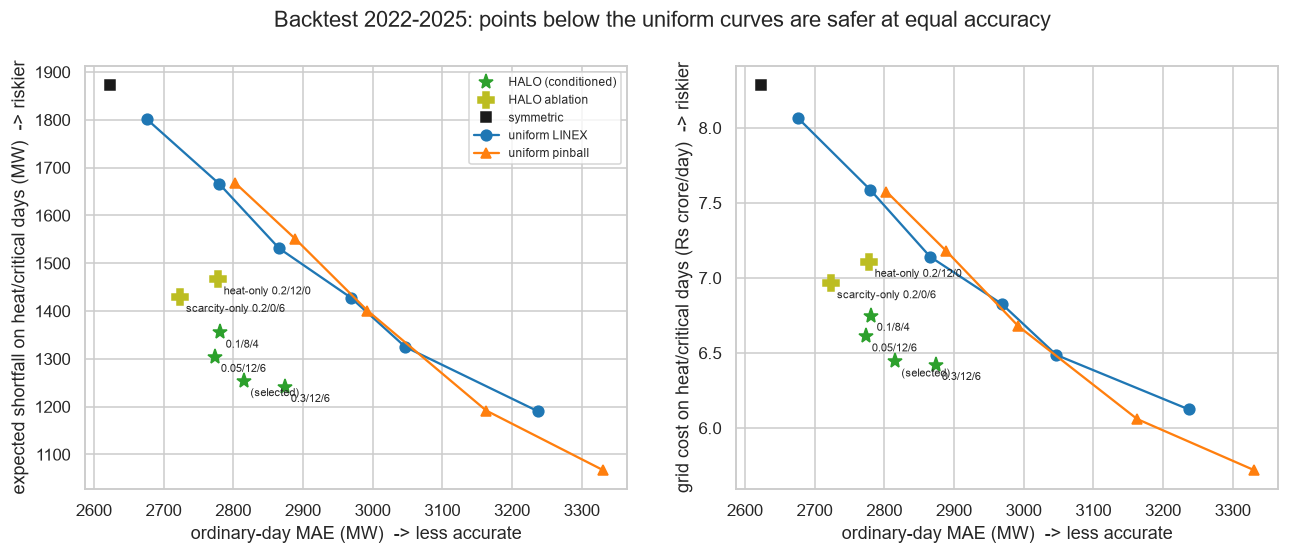

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
styles = {"symmetric": ("k", "s"), "uniform LINEX": ("tab:blue", "o"), "uniform pinball": ("tab:orange", "^"),
          "HALO (conditioned)": ("tab:green", "*"), "HALO ablation": ("tab:olive", "P")}
for a_, y, lab in zip(ax, ["expected_shortfall_hc_MW", "cost_hc_crore"],
                      ["expected shortfall on heat/critical days (MW)", "grid cost on heat/critical days (Rs crore/day)"]):
    for fam, g in front.groupby("family"):
        c, mk = styles[fam]
        g = g.sort_values("MAE_ordinary_MW")
        a_.plot(g["MAE_ordinary_MW"], g[y], marker=mk, color=c, ls="-" if fam.startswith("uniform") else "",
                ms=10 if "HALO" in fam else 7, label=fam)
        if "HALO" in fam:
            for n, r in g.iterrows():
                a_.annotate(n.replace("HALO ", ""), (r["MAE_ordinary_MW"], r[y]), fontsize=7, xytext=(4, -10),
                            textcoords="offset points")
    a_.set(xlabel="ordinary-day MAE (MW)  -> less accurate", ylabel=lab + "  -> riskier")
ax[0].legend(fontsize=8)
fig.suptitle("Backtest 2022-2025: points below the uniform curves are safer at equal accuracy")
savefig("08_frontier"); plt.show()

Every HALO variant sits **below** both uniform curves: at the same ordinary-day accuracy it has lower shortfall and lower cost.
That holds for four different HALO settings, so it is not one lucky configuration. The confidence intervals:

In [7]:
fb = E.exp_frontier_bootstrap(n_boot=1000)
fb

,eval_set,halo,vs,statistic,gain_at_equal_accuracy,ci_low,ci_high,p_value
0,all folds 2022-2025,HALO (selected),uniform LINEX,cost_hc_crore,-0.956,-1.405,-0.479,0.000
1,all folds 2022-2025,HALO (selected),uniform LINEX,expected_shortfall_hc_MW,-355.702,-482.124,-223.926,0.000
2,all folds 2022-2025,HALO (selected),uniform LINEX,under_rate_hc_pct,-9.923,-14.004,-5.811,0.000
3,all folds 2022-2025,HALO (selected),uniform pinball,cost_hc_crore,-1.072,-1.387,-0.435,0.000
4,all folds 2022-2025,HALO (selected),uniform pinball,expected_shortfall_hc_MW,-396.285,-467.783,-216.421,0.000
5,all folds 2022-2025,HALO (selected),uniform pinball,under_rate_hc_pct,-10.218,-13.795,-3.815,0.000
6,OOS folds 2022/2023/2025,HALO (selected),uniform LINEX,cost_hc_crore,-0.512,-1.027,-0.035,0.034
7,OOS folds 2022/2023/2025,HALO (selected),uniform LINEX,expected_shortfall_hc_MW,-227.057,-372.064,-102.291,0.000
8,OOS folds 2022/2023/2025,HALO (selected),uniform LINEX,under_rate_hc_pct,-9.552,-13.909,-5.105,0.000
9,OOS folds 2022/2023/2025,HALO (selected),uniform pinball,cost_hc_crore,-0.751,-1.135,-0.111,0.011


**Reading E2**
* The **selected HALO** beats uniform LINEX *and* uniform pinball at equal accuracy on all three risk statistics, significantly,
  including on the OOS folds. **This is the central novelty claim, and it is supported.**
* **Scarcity-only** conditioning is significant everywhere.
* **Heat-only** conditioning is significant on all folds but **not** on the OOS folds (p > 0.1). The heat term alone is not robust
  outside the record-heat year 2024. The next test checks what it adds on top of scarcity.

In [8]:
cc = E.exp_component_contrast(n_boot=2000)
cc

,eval_set,statistic,scarcity_only,full_HALO,diff,ci_low,ci_high,p_value
0,all folds 2022-2025,expected_shortfall_heatwave_MW,"1,404.800","1,066.436",-338.364,-454.184,-223.387,0.000
1,all folds 2022-2025,expected_shortfall_hc_MW,"1,430.209","1,253.961",-176.248,-241.619,-111.228,0.000
2,all folds 2022-2025,cost_hc_crore,6.966,6.445,-0.522,-0.777,-0.283,0.000
3,all folds 2022-2025,under_rate_hc_pct,55.381,52.493,-2.887,-5.656,0.272,0.088
4,all folds 2022-2025,MAE_ordinary_MW,"2,723.428","2,815.824",92.396,48.689,139.674,0.000
5,OOS folds 2022/2023/2025,expected_shortfall_heatwave_MW,"1,204.962",905.116,-299.846,-472.024,-160.599,0.000
6,OOS folds 2022/2023/2025,expected_shortfall_hc_MW,"1,313.584","1,168.710",-144.874,-217.153,-80.615,0.000
7,OOS folds 2022/2023/2025,cost_hc_crore,6.360,5.901,-0.459,-0.739,-0.214,0.000
8,OOS folds 2022/2023/2025,under_rate_hc_pct,54.455,52.475,-1.980,-5.079,1.695,0.385
9,OOS folds 2022/2023/2025,MAE_ordinary_MW,"2,694.347","2,810.824",116.478,65.813,173.568,0.000


Adding the heat term to scarcity-only HALO (same `a0`, same scarcity strength) **significantly lowers the shortfall on heatwave days
and on heat/critical days**, including on the OOS folds. It also raises ordinary-day MAE. So the **heatwave conditioning acts where it
is supposed to (heatwave days), and both conditioning signals are needed for the full effect.**

## E3 · Feature ablations: explicit regime features (G3) and heat accumulation / humidity (G7)

In [9]:
fa = E.exp_feature_ablation()
fa

,model,feature_set,n_features,under_rate_hc_pct,reserve_breach_hc_pct,expected_shortfall_hc_MW,expected_shortfall_heatwave_MW,cost_hc_crore,cost_all_crore,MAE_ordinary_MW,MAPE_all_pct
0,L2,full,309,66.142,4.724,"1,872.895","1,880.353",8.286,6.558,"2,622.659",1.324
1,HALO,full,309,52.493,2.100,"1,253.961","1,066.436",6.445,5.682,"2,815.824",1.404
2,L2,no_regime_features (G3),257,65.879,4.724,"1,864.656","1,823.297",8.248,6.573,"2,631.481",1.325
3,HALO,no_regime_features (G3),257,50.656,1.575,"1,262.525","1,134.727",6.486,5.726,"2,828.421",1.410
4,L2,no_accumulation_features (G7a),263,66.142,5.249,"1,886.067","1,879.058",8.314,6.538,"2,615.109",1.319
5,HALO,no_accumulation_features (G7a),263,53.018,2.100,"1,308.671","1,160.848",6.653,5.803,"2,822.954",1.412
6,L2,no_humidity_coupling (G7b),273,64.829,4.462,"1,877.361","1,937.919",8.300,6.526,"2,605.202",1.316
7,HALO,no_humidity_coupling (G7b),273,53.018,2.100,"1,255.997","1,079.107",6.459,5.745,"2,844.502",1.415


In [10]:
fab = E.ablation_bootstrap(n_boot=2000)
fab

,model,ablation,statistic,full,ablated,diff,ci_low,ci_high,p_value
0,L2,no_regime_features,expected_shortfall_hc_MW,"1,872.895","1,864.656",-8.239,-52.672,39.165,0.788
1,L2,no_regime_features,cost_hc_crore,8.286,8.248,-0.038,-0.214,0.154,0.722
2,L2,no_regime_features,MAE_ordinary_MW,"2,622.659","2,631.481",8.822,-22.326,37.949,0.570
3,L2,no_accumulation_features,expected_shortfall_hc_MW,"1,872.895","1,886.067",13.172,-31.162,61.664,0.533
4,L2,no_accumulation_features,cost_hc_crore,8.286,8.314,0.029,-0.147,0.223,0.726
5,L2,no_accumulation_features,MAE_ordinary_MW,"2,622.659","2,615.109",-7.550,-40.334,23.399,0.594
6,L2,no_humidity_coupling,expected_shortfall_hc_MW,"1,872.895","1,877.361",4.466,-43.145,51.397,0.842
7,L2,no_humidity_coupling,cost_hc_crore,8.286,8.300,0.014,-0.168,0.191,0.877
8,L2,no_humidity_coupling,MAE_ordinary_MW,"2,622.659","2,605.202",-17.457,-49.361,13.675,0.277
9,HALO,no_regime_features,expected_shortfall_hc_MW,"1,253.961","1,262.525",8.563,-30.356,51.395,0.646


**Reading E3 (including the negative results)**
* **Heat-accumulation features (G7a):** removing them **significantly worsens HALO** (expected shortfall and cost on heat/critical
  days rise, p < 0.01) but does not change L2. Persistence and thermal-lag features matter *when the loss is heat-conditioned*: the
  heat-aware loss uses them to decide where to add margin.
* **Explicit regime features (G3, feature side):** removing them makes **no significant difference**. Trees recover heat effects from raw
  temperatures. So G3 is supported through the **loss conditioning** (E2), not through regime features.
* **Humidity coupling (G7b):** no significant effect at national scale. Not claimed.

## E4 · Does the clustering step help the national forecast?

In [11]:
sa = E.exp_spatial_ablation()
sa

,model,spatial_representation,n_features,under_rate_hc_pct,reserve_breach_hc_pct,expected_shortfall_hc_MW,expected_shortfall_heatwave_MW,cost_hc_crore,cost_all_crore,MAE_ordinary_MW,MAPE_all_pct
0,L2,zones,309,66.142,4.724,"1,872.895","1,880.353",8.286,6.558,"2,622.659",1.324
1,HALO,zones,309,52.493,2.100,"1,253.961","1,066.436",6.445,5.682,"2,815.824",1.404
2,L2,grid,219,66.404,4.462,"1,890.337","1,952.382",8.310,6.519,"2,637.969",1.326
3,HALO,grid,219,51.444,2.362,"1,241.713","1,085.940",6.385,5.787,"2,881.345",1.427
4,L2,national,69,68.241,4.462,"1,954.925","1,902.017",8.516,6.554,"2,619.250",1.318
5,HALO,national,69,49.081,2.100,"1,165.675",970.650,6.112,5.549,"2,856.345",1.410


**Negative result, reported honestly.** For the **national** target, the 8 data-driven zones are **not** better than the official grid
regions or than a single demand-weighted national average. HALO with national-average weather (69 features) is at least as good as
with zones (309 features). The useful ingredient is the **demand-weighted aggregation of state weather**, not the regional split.
Clustering remains useful as an interpretable description of India's thermal-demand geography (notebook 04) and for future regional
targets, but **we do not claim it improves this forecast**. We kept the zone-based model as the main model because that choice was
made before this ablation.

## E5 · Demand beyond the training range (G11, partial)

In [12]:
ls = E.exp_level_shift()
ls

,n_days,bias_MW,under_rate_pct,MAPE_pct,worst_shortfall_MW,all days: MAPE_all_pct,all days: under_rate_hc_pct
L2 raw-MW target,162.000,"-18,468.085",100.000,8.649,"38,888.410",3.758,98.425
L2 (% target),162.000,"-1,259.916",71.605,1.402,"10,472.552",1.324,66.142
HALO (% target),162.000,-50.759,58.642,1.351,"8,478.890",1.404,52.493


On the **162 backtest days whose peak is at or above 98 % of the highest peak in the training years**, an otherwise identical
LightGBM trained on raw MW under-forecasts **every one** of them (trees cannot extrapolate). Our "% above last week" target
transform cuts the error from about 8.6 % to about 1.4 % MAPE, and HALO nearly removes the bias. This is evidence for robustness to
**growth-driven** distribution shift. Climate-driven future extremes (scenario testing) are **not** covered, so G11 is only partly addressed.

## E6 · Standard metrics hide peak risk (G6)

In [13]:
md_ = E.exp_metric_disagreement()
md_

,under_rate_hc_pct,reserve_breach_hc_pct,expected_shortfall_hc_MW,expected_shortfall_heatwave_MW,cost_hc_crore,cost_all_crore,MAE_ordinary_MW,MAPE_all_pct,RMSE_all_MW,rank: under_rate_hc_pct,rank: reserve_breach_hc_pct,rank: expected_shortfall_hc_MW,rank: expected_shortfall_heatwave_MW,rank: cost_hc_crore,rank: cost_all_crore,rank: MAE_ordinary_MW,rank: MAPE_all_pct,rank: RMSE_all_MW
lgbm_l2,66.142,4.724,"1,872.895","1,880.353",8.286,6.558,"2,622.659",1.324,"3,808.913",6.000,6.000,6.000,6.000,6.000,6.000,1.000,1.000,1.000
lgbm_quantile60,60.630,2.887,"1,568.904","1,562.092",7.227,5.808,"2,804.051",1.383,"4,124.989",3.000,3.000,3.000,4.000,3.000,3.000,4.000,4.000,4.000
lgbm_quantile80,44.357,0.787,903.695,887.080,5.321,5.059,"3,619.590",1.712,"5,132.814",1.000,1.000,1.000,1.000,1.000,1.000,6.000,6.000,6.000
lgbm_prototype,62.730,3.412,"1,651.883","1,503.199",7.603,6.140,"2,722.340",1.360,"3,910.116",4.000,4.000,4.000,3.000,4.000,4.000,3.000,3.000,2.000
lgbm_linex,65.617,3.937,"1,801.373","1,766.750",8.066,6.355,"2,676.004",1.347,"3,957.430",5.000,5.000,5.000,5.000,5.000,5.000,2.000,2.000,3.000
lgbm_halo,52.493,2.100,"1,253.961","1,066.436",6.445,5.682,"2,815.824",1.404,"4,141.565",2.000,2.000,2.000,2.000,2.000,2.000,5.000,5.000,5.000
Kendall tau vs MAPE ranking,-1.000,-1.000,-1.000,-0.867,-1.000,-1.000,1.000,1.000,0.867,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


The model ranking by MAPE is **exactly reversed** by every peak-risk metric (Kendall tau = -1). A study that reports only MAPE/RMSE
would pick the model that is worst on heat and record days. That is direct empirical support for G6, and it is why our evaluation
framework reports regime-specific shortfall, reserve-breach and cost metrics.

## E7 · Lightweight and explainable (G9, partial)

In [14]:
E.exp_lightweight()

,train_rows,features,train_seconds,predict_365_days_ms,model_file_kB
LGBM-L2,"2,187.000",309.000,2.401,9.881,"1,073.720"
LGBM-HALO,"2,187.000",309.000,1.629,6.429,649.550


Training HALO on 2,187 days x 309 features takes about 2 s on a laptop CPU, forecasting a year takes milliseconds, and the model is under 1 MB.
Notebook 07 provides exact TreeSHAP attributions. We did not run a user study of interpretability, so G9 is only partly addressed.

## Gap-by-gap verdict (computed from the tables above)

In [15]:
def p(df, **kw):
    q = df.copy()
    for k, v in kw.items():
        q = q[q[k] == v]
    d = q["diff"] if "diff" in q else q["gain_at_equal_accuracy"]
    return float(q["p_value"].iloc[0]), float(d.iloc[0])

def verdict(ok, partial=False):
    if ok and not partial:
        return "SUPPORTED"
    return "PARTIALLY SUPPORTED" if (ok or partial) else "NOT SUPPORTED"

OOS_SIG = "backtest OOS folds (2022, 2023, 2025)"
OOS_FB = "OOS folds 2022/2023/2025"
pv_g1, d_g1 = p(sig, eval_set=OOS_SIG, baseline="lgbm_l2", statistic="expected_shortfall_hc_MW")
pv_g2, d_g2 = p(sig, eval_set=OOS_SIG, baseline="lgbm_l2", statistic="under_rate_hc_pct")
pv_g4, d_g4 = p(fb, eval_set=OOS_FB, halo="HALO (selected)", vs="uniform pinball", statistic="expected_shortfall_hc_MW")
pv_g5, d_g5 = p(fb, eval_set=OOS_FB, halo="HALO (selected)", vs="uniform LINEX", statistic="expected_shortfall_hc_MW")
pv_g3, d_g3 = p(cc, eval_set=OOS_FB, statistic="expected_shortfall_heatwave_MW")
pv_g7, d_g7 = p(fab, model="HALO", ablation="no_accumulation_features", statistic="expected_shortfall_hc_MW")
tau = float(md_.loc["Kendall tau vs MAPE ranking", "expected_shortfall_hc_MW"])
rows = [
 ("G1 symmetric losses ignore costlier under-forecasts", verdict(pv_g1 < .05),
  f"HALO vs L2, OOS folds: expected shortfall {d_g1:+.0f} MW/day (p={pv_g1:.3f}); ordinary MAE also rises (stated cost)"),
 ("G2 rare heatwave regimes poorly forecast", verdict(pv_g2 < .05),
  f"heat/critical under-forecast rate {d_g2:+.1f} pts vs L2, OOS (p={pv_g2:.3f})"),
 ("G3 heatwave as explicit conditioning regime", verdict(pv_g3 < .05, partial=True),
  f"via the LOSS: heat term adds {d_g3:+.0f} MW heatwave-day shortfall change beyond scarcity, OOS (p={pv_g3:.3f}); regime FEATURES add nothing (E3)"),
 ("G4 custom asymmetric objective inside boosting", verdict(pv_g4 < .05),
  f"vs pinball at equal ordinary accuracy, OOS: {d_g4:+.0f} MW expected shortfall (p={pv_g4:.3f})"),
 ("G5 asymmetry adapted to heat severity / grid state", verdict(pv_g5 < .05),
  f"vs constant-asymmetry LINEX at equal accuracy, OOS: {d_g5:+.0f} MW (p={pv_g5:.3f})"),
 ("G6 MAPE/RMSE hide peak under-forecasting", verdict(tau < -0.5),
  f"Kendall tau(MAPE ranking, shortfall ranking) = {tau:.2f}"),
 ("G7 heat accumulation as engineered features", verdict(pv_g7 < .05, partial=True),
  f"removing accumulation features: HALO shortfall {d_g7:+.0f} MW (p={pv_g7:.3f}); no effect for L2; humidity: none"),
 ("G8 Indian grid, rapidly growing cooling load", "SUPPORTED (scope)",
  "All-India 2019-2025, IMD official heatwave rules, record 2024 heatwave included"),
 ("G9 lightweight, interpretable models", "PARTIALLY SUPPORTED", "~2 s training, <1 MB, TreeSHAP; no user study"),
 ("G10 asymmetric point vs probabilistic methods", "PARTIALLY SUPPORTED",
  "compared with pinball (quantile) curves; conformal methods not tested"),
 ("G11 distribution shift", "PARTIALLY SUPPORTED", "growth-driven shift handled (E5); climate-scenario shift not tested"),
 ("(design) data-driven zone clustering helps", "NOT SUPPORTED", "national-average weather performs as well (E4)"),
]
verdicts = pd.DataFrame(rows, columns=["gap / claim", "verdict", "evidence"])
verdicts.to_csv(C.METRICS_DIR / "evidence_gap_verdicts.csv", index=False)
verdicts

,gap / claim,verdict,evidence
0,G1 symmetric losses ignore costlier under-fore...,SUPPORTED,"HALO vs L2, OOS folds: expected shortfall -536..."
1,G2 rare heatwave regimes poorly forecast,SUPPORTED,heat/critical under-forecast rate -13.2 pts vs...
2,G3 heatwave as explicit conditioning regime,PARTIALLY SUPPORTED,via the LOSS: heat term adds -300 MW heatwave-...
3,G4 custom asymmetric objective inside boosting,SUPPORTED,"vs pinball at equal ordinary accuracy, OOS: -2..."
4,G5 asymmetry adapted to heat severity / grid s...,SUPPORTED,"vs constant-asymmetry LINEX at equal accuracy,..."
5,G6 MAPE/RMSE hide peak under-forecasting,SUPPORTED,"Kendall tau(MAPE ranking, shortfall ranking) =..."
6,G7 heat accumulation as engineered features,PARTIALLY SUPPORTED,removing accumulation features: HALO shortfall...
7,"G8 Indian grid, rapidly growing cooling load",SUPPORTED (scope),"All-India 2019-2025, IMD official heatwave rul..."
8,"G9 lightweight, interpretable models",PARTIALLY SUPPORTED,"~2 s training, <1 MB, TreeSHAP; no user study"
9,G10 asymmetric point vs probabilistic methods,PARTIALLY SUPPORTED,compared with pinball (quantile) curves; confo...
